In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Visuals ko Jupyter mein inline dekhne ke liye
%matplotlib inline
# Seaborn ka default theme set karna
sns.set_theme(style="darkgrid")

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:
# Lap times aur Races ka data load karna
try:
    lap_times = pd.read_csv('../data/lap_times.csv')
    races = pd.read_csv('../data/races.csv')
    drivers = pd.read_csv('../data/drivers.csv')
    print("Data loaded successfully!")
except FileNotFoundError as e:
    print(f"Error: {e}. Check karo ki CSV files sahi folder mein hain ya nahi.")

Data loaded successfully!


In [3]:
# Lap times data ki pehli 5 rows
display(lap_times.head())

# Missing values check karna
print("\n--- Missing Values in Lap Times ---")
print(lap_times.isnull().sum())

# Data types check karna
print("\n--- Data Types ---")
print(lap_times.info())

,raceId,driverId,lap,position,time,milliseconds
0,841,20,1,1,1:38.109,98109
1,841,20,2,1,1:33.006,93006
2,841,20,3,1,1:32.713,92713
3,841,20,4,1,1:32.803,92803
4,841,20,5,1,1:32.342,92342



--- Missing Values in Lap Times ---
raceId          0
driverId        0
lap             0
position        0
time            0
milliseconds    0
dtype: int64

--- Data Types ---
<class 'pandas.DataFrame'>
RangeIndex: 589081 entries, 0 to 589080
Data columns (total 6 columns):
 #   Column        Non-Null Count   Dtype
---  ------        --------------   -----
 0   raceId        589081 non-null  int64
 1   driverId      589081 non-null  int64
 2   lap           589081 non-null  int64
 3   position      589081 non-null  int64
 4   time          589081 non-null  str  
 5   milliseconds  589081 non-null  int64
dtypes: int64(5), str(1)
memory usage: 27.0 MB
None


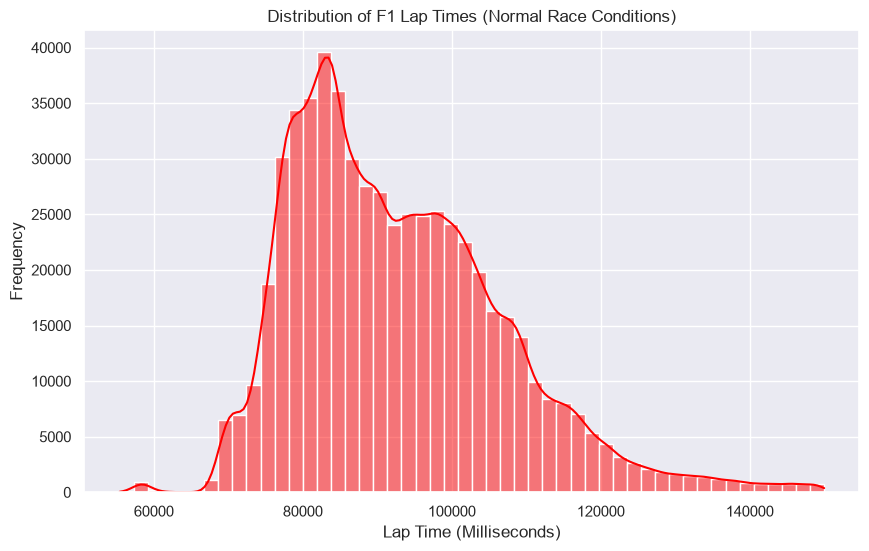

In [5]:
# Lap time distribution plot karna
plt.figure(figsize=(10, 6))
# Outliers hatane ke liye sirf normal race lap times (e.g. < 150000 ms or 2.5 mins) plot kar rahe hain
sns.histplot(lap_times[lap_times['milliseconds'] < 150000]['milliseconds'], bins=50, kde=True, color='red')

plt.title('Distribution of F1 Lap Times (Normal Race Conditions)')
plt.xlabel('Lap Time (Milliseconds)')
plt.ylabel('Frequency')
plt.show()


In [6]:
# Lap times dataframe ko races dataframe ke sath merge karna
# Sirf zaroori columns le rahe hain (year aur circuitId)
merged_df = pd.merge(lap_times, races[['raceId', 'year', 'circuitId']], on='raceId', how='left')

print("Merged Dataframe ki shape:", merged_df.shape)
display(merged_df.head())


Merged Dataframe ki shape: (589081, 8)


,raceId,driverId,lap,position,time,milliseconds,year,circuitId
0,841,20,1,1,1:38.109,98109,2011,1
1,841,20,2,1,1:33.006,93006,2011,1
2,841,20,3,1,1:32.713,92713,2011,1
3,841,20,4,1,1:32.803,92803,2011,1
4,841,20,5,1,1:32.342,92342,2011,1


In [7]:
# Sirf 2014 aur uske baad ka data filter karna
df_recent = merged_df[merged_df['year'] >= 2014].copy()

# Zaroori features (X) aur target variable (y) select karna
# lap: Lap number (indicates fuel burning off and tire wear)
selected_features = ['circuitId', 'driverId', 'lap']
target = 'milliseconds'

# Naya dataframe jisme sirf modeling ka data ho
df_model = df_recent[selected_features + [target]].dropna()

print(f"2014 ke baad ke total records: {len(df_model)}")

2014 ke baad ke total records: 248144


In [8]:
from sklearn.model_selection import train_test_split

X = df_model[selected_features]
y = df_model[target]

# Data ko 80% training aur 20% testing mein split karna
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training features shape: {X_train.shape}")
print(f"Testing features shape: {X_test.shape}")


Training features shape: (198515, 3)
Testing features shape: (49629, 3)


In [9]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

print("Training models... (Isme thoda time lag sakta hai)")

# 1. Linear Regression (Baseline Model)
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
lr_preds = lr_model.predict(X_test)
print("Linear Regression training complete.")

# 2. Random Forest (Advanced Model)
# n_estimators=20 rakha hai taaki jaldi train ho, fine-tuning baad mein karenge
rf_model = RandomForestRegressor(n_estimators=20, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)
rf_preds = rf_model.predict(X_test)
print("Random Forest training complete.")

Training models... (Isme thoda time lag sakta hai)
Linear Regression training complete.
Random Forest training complete.


In [10]:
# Mean Absolute Error (MAE) calculate karna (Seconds mein)
lr_mae = mean_absolute_error(y_test, lr_preds) / 1000
rf_mae = mean_absolute_error(y_test, rf_preds) / 1000

print(f"--- Model Error (Kam error = Behtar Model) ---")
print(f"Linear Regression MAE: {lr_mae:.2f} Seconds")
print(f"Random Forest MAE: {rf_mae:.2f} Seconds")

--- Model Error (Kam error = Behtar Model) ---
Linear Regression MAE: 16.17 Seconds
Random Forest MAE: 13.08 Seconds
